# Sesión 7 — Repaso

Este notebook contiene enunciados completos de ejercicios basados en las sesiones 1–6. Usa numpy, pandas, matplotlib, scipy y statsmodels.

---

## Ejercicio 1 — Valor de una cartera (producto escalar)

Tienes tres activos con las siguientes cantidades y precios:

- A: 40 acciones a 25 €
- B: 20 acciones a 60 €
- C: 10 acciones a 100 €

1. Representa la cartera mediante vectores (`quantities`, `prices`).
2. Calcula el valor total usando el producto escalar.

In [1]:
import numpy as np

# 1. Representa la cartera mediante vectores (quantities, prices).
quantities = np.array([40, 20, 10])
prices = np.array([25, 60, 100])

In [2]:
# 2. Calcula el valor total usando el producto escalar.
quantities @ prices

np.int64(3200)

## Ejercicio 2 — Rentabilidad anual de una cartera (producto matriz por vector)

Supón la siguiente tabla de rendimientos medios (decimales):


| Año | A | B | C |
|-----|---|---|---|
| 2020 | 0.04 | 0.08 | -0.02 |
| 2021 | 0.06 | 0.05 | 0.10 |
| 2022 | -0.03 | 0.07 | 0.04 |

Y una cartera $w = \begin{pmatrix}
0.4 \\
0.4 \\
0.2
\end{pmatrix}$.


* Representa la tabla como una matriz de rendimientos 𝑅
* Calcula el rendimiento medio de la cartera $w$ en cada año usando el producto de matrices.
* Dame una cartera **normalizada** (suma de pesos igual a 1) que mejore el rendimiento total al cabo de los 3 años



In [3]:
# Representa la tabla como una matriz de rendimientos 𝑅
R = np.array([[0.04, 0.08, -0.02],
              [0.06, 0.05, 0.10],
              [-0.03, 0.07, 0.04]])

In [9]:
# Calcula el rendimiento medio de la cartera  𝑤  en cada año usando el producto de matrices.
w = np.array([0.4, 0.4, 0.2])
R @ w

array([0.044, 0.064, 0.024])

In [10]:
# Dame una cartera normalizada (suma de pesos igual a 1) que mejore el rendimiento total al cabo de los 3 años.
w_prime = np.array([0, 1, 0])
R @ w_prime

array([0.08, 0.05, 0.07])

In [11]:
sum(R @ w), sum(R @ w_prime)

(np.float64(0.132), np.float64(0.2))

## Ejercicio 3 — Cadena de Markov
Una acción puede estar al alza (S) o a la baja (B).
La matriz de transición es:

$$
P =
\begin{pmatrix}
0.7 & 0.4 \\
0.3 & 0.6
\end{pmatrix}
$$

* Si hoy está al alza, ¿cuál es la probabilidad de que esté al alza dentro de 2 días?
* ¿A qué distribución de probabilidades tiende la cadena?
* ¿Depende esta distribución de si, a día de hoy, el mercado está a la alza o a la baja?

In [14]:
# Si hoy está al alza, ¿cuál es la probabilidad de que esté al alza dentro de 2 días?
P = np.array([[0.7,0.4],[0.3,0.6]])
P_square = np.linalg.matrix_power(P,2)
initial_state = np.array([1,0])

P_square@initial_state


array([0.61, 0.39])

In [16]:
# ¿A qué distribución de probabilidades tiende la cadena?
P_power = np.linalg.matrix_power(P,1000)
initial_state = np.array([1,0])

P_power@initial_state

array([0.57142857, 0.42857143])

In [17]:
# ¿Depende esta distribución de si, a día de hoy, el mercado está a la alza o a la baja?
initial_state_alt = np.array([0,1])

P_power@initial_state_alt

array([0.57142857, 0.42857143])

## Ejercicio 4 — Distribución binomial

Un trader acierta el 60 % de las veces. Sea $X$ la variable aleatoria que cuenta el número de éxitos en 5 operaciones.
* Probabilidad de acertar exactamente 3 de 5 operaciones.
* Probabilidad de acertar al menos 4.

In [18]:
from scipy.stats import binom

n = 5
p = 0.6

# Probabilidad de acertar exactamente 3 de 5 operaciones.
binom.pmf(3,n,p)

np.float64(0.3455999999999997)

In [19]:
# Probabilidad de acertar al menos 4.
binom.pmf(4,n,p) + binom.pmf(5,n,p)

np.float64(0.3369600000000001)

In [20]:
# Alternativamente
1 - binom.cdf(3,n,p)

np.float64(0.3369599999999999)

## Ejercicio 5 — Distribución normal

Las rentabilidades diarias de un fondo siguen $N(0.001,0.02^2)$. Responde a las preguntas:
* Cuál es la probabilidad de perder dinero un día.
* Calcula la probabilidad de ganar más del 3 %.
* Value at Risk al 95 % (aka el percentil 5% de la distribución).

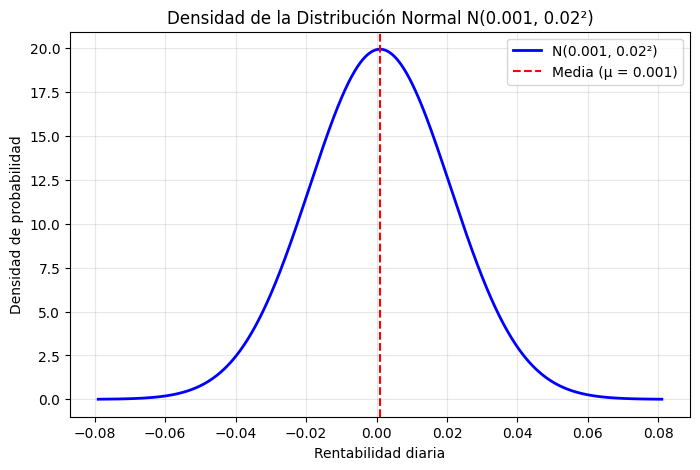

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Parámetros de la distribución
mu = 0.001
sigma = 0.02

# Generar puntos en el eje x (± 4 desviaciones estándar)
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)
y = norm.pdf(x, mu, sigma)

# Graficar la densidad de probabilidad
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=f'N({mu}, {sigma}²)', color='blue', linewidth=2)
plt.title('Densidad de la Distribución Normal N(0.001, 0.02²)')
plt.xlabel('Rentabilidad diaria')
plt.ylabel('Densidad de probabilidad')
plt.axvline(mu, color='red', linestyle='--', label=f'Media (μ = {mu})')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [25]:
# Cuál es la probabilidad de perder dinero un día.
from scipy.stats import norm

mu, sigma = 0.001, 0.02
norm.cdf(0, mu, sigma)

np.float64(0.4800611941616275)

In [24]:
# Calcula la probabilidad de ganar más del 3 %.
1 - norm.cdf(0.03, mu, sigma)

np.float64(0.0735292596096484)

In [26]:
# Value at Risk al 95 % (aka el percentil 5% de la distribución).
norm.ppf(0.05, mu, sigma)

np.float64(-0.03189707253902946)

## Ejercicio 6 — IC para la media (σ desconocida)

Tenemos una muestra de $n=25$ rendimientos diarios con media $\bar x= 0.5$ % y desviación estándar muestral $s = 1.2$ %.
* Calcula el IC 95 % para la media.
* ¿Cómo cambiaría tu IC si la volatilidad de los rendimientos hubiese sido mayor?

In [28]:
import scipy.stats as st

# Calcula el IC 95 % para la media.
n = 25
media = 0.5
s = 1.2
scale = s/np.sqrt(n)

st.t.interval(confidence = .95, df = n-1, loc = media, scale = scale)

(np.float64(0.004664345209275111), np.float64(0.9953356547907248))

In [29]:
# ¿Cómo cambiaría tu IC si la volatilidad de los rendimientos hubiese sido mayor?
s = 5
scale = s/np.sqrt(n)

st.t.interval(confidence = .95, df = n-1, loc = media, scale = scale)

(np.float64(-1.5638985616280205), np.float64(2.5638985616280205))

## Ejercicio 7 — IC para una proporción

Observando los movimientos de un fondo, vemos que de 200 días sube en 110.
* Calcula el IC 95% para la probabilidad de subida.
* ¿Cómo cambiaría la proporción muestral si en 400 días hubieses visto 220 subidas? ¿El IC 95% sería el mismo?

In [32]:
# Calcula el IC 95% para la probabilidad de subida.
count = 110
n = 200

p_hat = count/n
scale = np.sqrt(p_hat * (1 - p_hat) / n)

st.norm.interval(confidence = 0.95, loc=p_hat, scale=scale)

(np.float64(0.4810521552867026), np.float64(0.6189478447132974))

In [33]:
# ¿Cómo cambiaría la proporción muestral si en 400 días hubieses visto 220 subidas? ¿El IC 95% sería el mismo?
count = 220
n = 400

p_hat = count/n
scale = np.sqrt(p_hat * (1 - p_hat) / n)

st.norm.interval(confidence = 0.95, loc=p_hat, scale=scale)

(np.float64(0.5012465114550304), np.float64(0.5987534885449697))

## Ejercicio 8 — Test para media (σ desconocida)

Una estrategia afirma tener rendibilidad media diaria mejor que el 0.3 %. A partir de la siguiente muestra, ¿se puede afirmar con nivel de confianza del 95 % que eso es cierto?

In [34]:
import numpy as np

rendibilidades = np.array([-0.0029,  0.0364,  0.0356,  0.0457,  0.1649,  0.0489, -0.0209,
        0.0999,  0.1224, -0.1193,  0.0632,  0.0736, -0.0263,  0.1411,
       -0.0115,  0.0161, -0.0138,  0.0051, -0.1061, -0.1405,  0.163 ,
       -0.0812, -0.0956, -0.2118, -0.0604, -0.1288,  0.1677,  0.1045,
       -0.0653,  0.2287,  0.1017, -0.029 , -0.2464,  0.2326, -0.1355,
       -0.161 ,  0.1058,  0.2475,  0.1419,  0.0599])

In [36]:
rendibilidades.mean()

np.float64(0.018747499999999993)

In [37]:
from scipy.stats import ttest_1samp

ttest_1samp(rendibilidades, popmean = 0.003, alternative='greater')

TtestResult(statistic=np.float64(0.8091092405103046), pvalue=np.float64(0.21168058737954087), df=np.int64(39))

<Axes: ylabel='Count'>

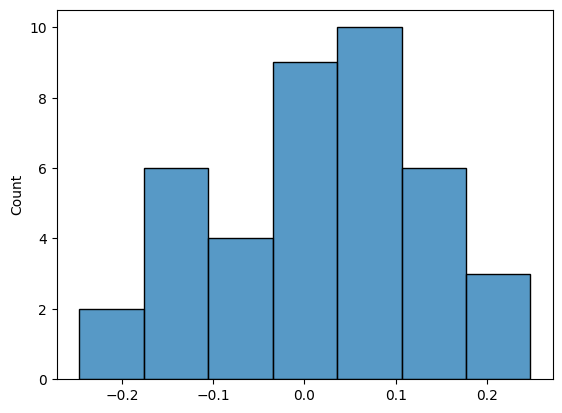

In [38]:
import seaborn as sns
sns.histplot(rendibilidades)

## Ejercicio 9 — Test para proporción

De 100 operaciones en bolsa, 60 fueron ganadoras.
¿Se puede afirmar al 95% de confianza que la probabilidad de ganar es mayor al 50 %? ¿Y si observamos 30 ganadoras de un total de 50 operaciones?

In [40]:
from statsmodels.stats.proportion import proportions_ztest
count = 60
n= 100

zstat, pvalue = proportions_ztest(count, n, value=0.5, alternative='larger')
pvalue

np.float64(0.02061341666858185)

In [41]:
zstat, pvalue = proportions_ztest(30, 50, value=0.5, alternative='larger')
pvalue

np.float64(0.07445733658938289)

## Ejercicio 10 — Exploratory Data Analysis & Visualización

Descárgate precios diarios de los tickers `['KO','PEP','^GSPC']` con `start_date = '2022-01-01'` y `end_date = '2023-01-01'` y realiza:
1) Calcula los retornos diarios.
2) Calcula sus estadísticos descriptivos. ¿Cuál tiene un retorno medio mayor? ¿Cuál tiene una volatilidad menor?
3) Muestra la distribución de los retornos. ¿Qué visualizaciones podrías usar?
4) Plotea la matriz de diagramas de dispersión. ¿Qué pares de retornos parecen estar más correlacionados? Comprueba tu intuición mediante el cálculo de la matriz de correlación.
5) Calcula la $\beta$ del ticker 'KO' y 'PEP' respecto al índice del mercado '^GSPC'. ¿Se trata de activos más sensibles o menos sensibles que el mercado?


In [44]:
import yfinance as yf

tickers = ['KO','PEP','^GSPC']
start_date = '2022-01-01'
end_date = '2023-01-01'

In [45]:
# Download data using yfinance
prices = yf.download(tickers, start=start_date, end=end_date)['Close']

/tmp/ipykernel_1901/3476733836.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  3 of 3 completed


In [46]:
prices.head()

Ticker,KO,PEP,^GSPC
Date,,,
2022-01-03,51.624321,148.083801,4796.560059
2022-01-04,52.486179,148.297821,4793.540039
2022-01-05,52.921459,148.802917,4700.580078
2022-01-06,52.642887,148.837143,4696.049805
2022-01-07,52.521008,149.025513,4677.029785


In [49]:
# 1. Calcula los retornos diarios.
returns = prices.pct_change().dropna()

In [50]:
returns.head()

Ticker,KO,PEP,^GSPC
Date,,,
2022-01-04,0.016695,0.001445,-0.000630
2022-01-05,0.008293,0.003406,-0.019393
2022-01-06,-0.005264,0.000230,-0.000964
2022-01-07,-0.002315,0.001266,-0.004050
2022-01-10,0.001658,0.000517,-0.001441


In [51]:
# 2. Calcula sus estadísticos descriptivos. ¿Cuál tiene un retorno medio mayor? ¿Cuál tiene una volatilidad menor?
returns.describe()

Ticker,KO,PEP,^GSPC
count,250.000000,250.000000,250.000000
mean,0.000475,0.000355,-0.000774
std,0.012423,0.012282,0.015252
min,-0.069626,-0.061963,-0.043237
25%,-0.006429,-0.005740,-0.010036
50%,0.001335,0.000753,-0.001609
75%,0.007421,0.007623,0.009505
max,0.038671,0.041823,0.055434


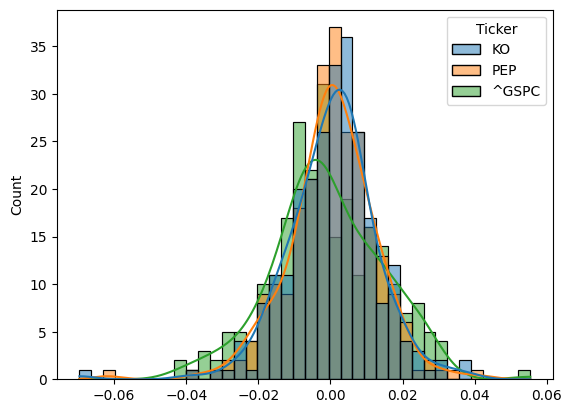

In [55]:
# 3. Muestra la distribución de los retornos. ¿Qué visualizaciones podrías usar?
sns.histplot(returns, kde = True)
plt.show()

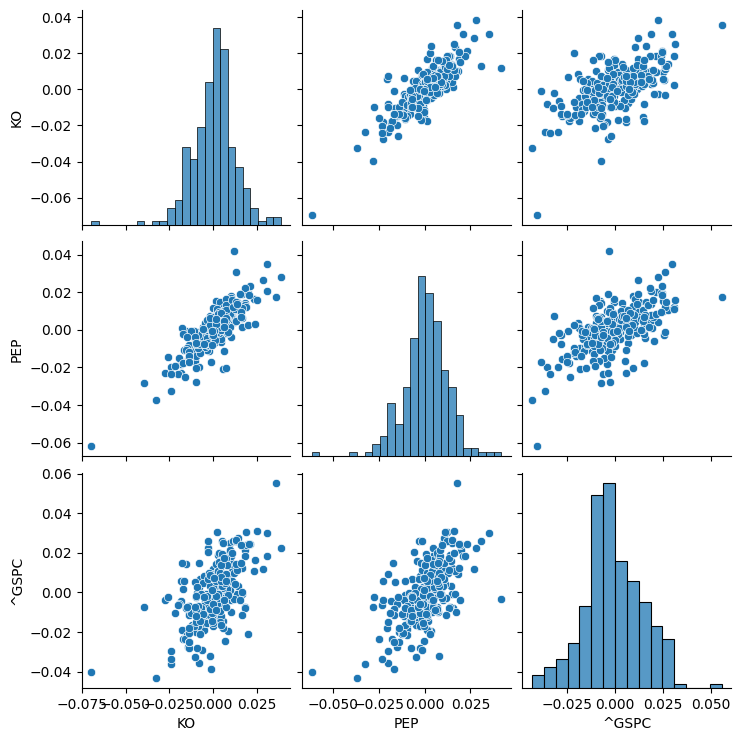

In [56]:
# 4. Plotea la matriz de diagramas de dispersión. ¿Qué pares de retornos parecen estar más correlacionados? Comprueba tu intuición mediante el cálculo de la matriz de correlación.

sns.pairplot(returns)
plt.show()

In [57]:
returns.corr()

Ticker,KO,PEP,^GSPC
Ticker,,,
KO,1.000000,0.837514,0.600610
PEP,0.837514,1.000000,0.608847
^GSPC,0.600610,0.608847,1.000000


In [59]:
# 5. Calcula la  𝛽  del ticker 'KO' y 'PEP' respecto al índice del mercado '^GSPC'. ¿Se trata de activos más sensibles o menos sensibles que el mercado?

from sklearn.linear_model import LinearRegression

# Formato necesario de variables para el modelo de regresión
X = returns['^GSPC'].values.reshape(-1, 1)
y = returns['KO']

# Create and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Beta
beta = model.coef_[0]
beta

np.float64(0.489231546483614)

In [60]:
# Formato necesario de variables para el modelo de regresión
X = returns['^GSPC'].values.reshape(-1, 1)
y = returns['PEP']

# Create and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Beta
beta = model.coef_[0]
beta

np.float64(0.49031135921483676)